# Workshop General Info

## Submitting the Assignment

Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All). There are no marks for "what my code used to do before I changed it".

Make sure you fill in any place that says `YOUR CODE HERE`. Answer any text-based questions and double-check that you have given any variables you create the names you are asked to give them.

A submission that passes all the tests will pass overall, but there are often marks for hidden tests you cannot see.

For submission via the nbgrader interface: once finished, go back to the "Assignments" tab and click submit. You can do this again if you are not happy with your answers. This submits a version of the notebook with all outputs cleared.

Please enter your name as a string, in the box below in case files go astray. E.g.:

```
NAME = "Albert Bartok-Partay"
```
Feedback will be released through the nbgrader interface: you can go back to the Assignments tab again to download it.

In [1]:
NAME = "Jabir Hussain"
# Restart Kernal + Run All Cells does not work here as a result of errors with the provided code for each simulation code cell. 
# I think there's an issue with the module for the BioChemistry Notebook, of which the simulation segment only works when adjusting the provided matplotlib code
# However, this has to be done in a separate cell rather than in the read-only animation cell provided.

In [2]:
# Only run this cell once.
!pip install --user quippy-ase 
!pip install --user tqdm

In [3]:
import sys
sys.path.insert(0, '/home/jovyan/.local/lib/python3.11/site-packages')

In [4]:
%matplotlib notebook

In [5]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.spatial import KDTree

## Ball bouncing in four corners

In this exercise, you will model the dynamics of a single moving particle as it is interacting with four soft corners. The interaction energy $V$ between the particle and any one of the corners is
$$
V(r < 1) = 100 (1-r^2)^4
$$
where $r$ is the distance between the particle and the corner. If the distance between the particle and the corner is greater than one, the interaction is zero. The force derived from this expression is
$$
F(r < 1) = -\frac{\mathrm{d}V}{\mathrm{d}r} = 800 r (1-r^2)^3
$$
Remember that this is the magnitude of the force and you need to multiply it by the direction to make it a vector.
The four corners are placed in
$$
x_C = \pm \frac{1}{2}
$$
$$
y_C = \pm \frac{\sqrt{3}}{2}
$$


In [6]:
# These are the coordinates of the corners.

corners = np.array(
[
    [-1/2,-np.sqrt(3)/2],
    [-1/2,np.sqrt(3)/2],
    [1/2,-np.sqrt(3)/2],
    [1/2,np.sqrt(3)/2]
])


In [7]:
def bounce(r):
    """This function implements the interaction of the particle with
    the corners. r, an numpy array, contains the x and y coordinate 
    of the particle."""
    
    # This is the difference vector between the particle's coordinate
    # and the corners.
    diff = r - corners
    
    # This contains the distance from all the corners.
    r_mag = np.linalg.norm(diff,axis=1)
    
    # This contains the unit vector of direction cosines pointing from
    # the particle from the corners.
    r_cos = diff/r_mag[:,None]
    
    # This implements the force magnitude
    f_mag = np.where(r_mag < 1, 800*r_mag*(1-r_mag**2)**3, 0)
    
    # This multiplies the force magnitude by the direction, to give the
    # force vectors.
    f = f_mag[:,None]*r_cos
    
    # Finally, all force contributions from the corners are summed up.
    # This is the force acting on the particle.
    return np.sum(f,axis=0)

Implement below the Velocity Verlet algorithm to propagate the position and velocity of the particle, given:
- `n` number of steps
- `r` initial positions
- `v` initial velocities
- `force` function accepting the position of the particles and returning the forces acting on it
- `dt` optional, the timestep
- `zero_momentum` optional, whether to subtract the mean velocity initially, thereby removing overall translation

The function should return a list of positions of the particle(s) in every time step as they are propagated.

The Velocity Verlet algorithm does the following steps:
1. $\mathbf{v}(t+\Delta t/2) = \mathbf{v}(t) + \frac{\mathbf{F(\mathbf{r}(t))}}{m}\frac{\Delta t}{2} $
1. $\mathbf{r}(t+\Delta t) = \mathbf{r}(t) + \mathbf{v}(t+\Delta t/2) \Delta t$
1. $\mathbf{v}(t+\Delta t) = \mathbf{v}(t+\Delta t/2) + \frac{\mathbf{F(\mathbf{r}(t+\Delta t))}}{m}\frac{\Delta t}{2} $

You should assume that the masses are stored in a global variable called `m`, which is `numpy` array.

In [8]:
def run(n,r_in,v_in,force,dt = 0.001,zero_momentum=True):
    r = r_in*1 # this makes a local copy
    v = v_in*1 # this makes a local copy
    # Calculate initial forces
    f = force(r)

    if zero_momentum:
        v_mean = np.sum(v*m[:,None],axis=0)/np.sum(m)
        v -= v_mean


    r_traj = []
    

    for i in range(n):
        # Step 1 in the Velocity Verlet algorithm
        v += 0.5*dt*f/m[:,None]
        # update using half-step velocity
        r += dt * v
        # update forces at new pos
        f = force(r)

        v += 0.5 * dt * f / m[:, None]
        r_traj.append(r*1)

    r_traj = np.array(r_traj)
    
    return r_traj

Now it is time to run your simulation! I set some initial conditions below.

In [9]:
n = 4000
m = np.ones(1)


r = np.array([
    [0.,0.]]
)

v = np.array(
    [[1.,1.]])

r_traj = run(n,r,v,bounce,zero_momentum=False)
# The shape of r_traj is (number of steps, number of particles, dimensionality) where dimensionality is 2.

Plot the trajectory of the particle below. Do not forget axis labels, legend or title, if needed.

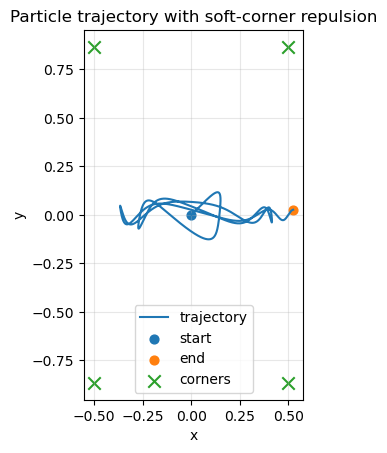

In [10]:
%matplotlib inline 
# plots don't work in the interactive notebook env
plt.figure()

x = r_traj[:, 0, 0]
y = r_traj[:, 0, 1]
plt.plot(x, y, lw=1.5, label="trajectory")

# mark start and end points
plt.scatter([x[0]], [y[0]], s=40, label="start")
plt.scatter([x[-1]], [y[-1]], s=40, label="end")

# show corners
plt.scatter(corners[:, 0], corners[:, 1], marker="x", s=80, label="corners")

plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Particle trajectory with soft-corner repulsion")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Below I placed some code which you can use to animate the trajectory. Just run the cell and see how the particle moves.

RuntimeError: x must be a sequence

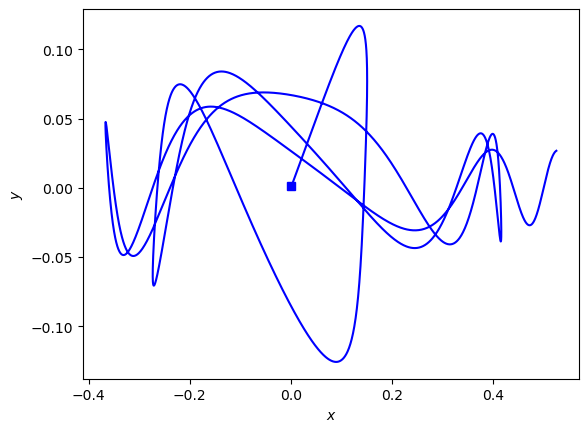

In [11]:
fig, ax = plt.subplots()
point0, = ax.plot(r_traj[0,0,0],r_traj[0,0,1],"bs")


ax.plot(r_traj[:,0,0],r_traj[:,0,1],"b-")

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")

def animate(i):
    point0.set_xdata(r_traj[i,0,0])
    point0.set_ydata(r_traj[i,0,1])
    
    return point0

ani = animation.FuncAnimation(
    fig, animate, frames=n,interval=10, blit=True)

# In case you want to save it as a movie 
#ani.save("bounce.mp4")

plt.show()

In the following, repeat your simulation, but starting with slightly different initial conditions. Use
$$ \mathbf{r}_0 = [0,0] $$
and
$$ \mathbf{v}_0 = [1+k \Delta v,1+k \Delta v] $$
where $k=0,1,2,\ldots,19$ and $\Delta v = 0.001$.

Collect all the trajectories in a dictionary called `r_traj_all`, where the key is `k` for each trajectory.

In [ ]:
r_traj_all = {} # the results should go in this dictionary
dv = 0.001

r_0 = np.array([[0., 0.]])   # (1,2)
vs  = np.array([[1., 1.]])   # (1,2)

for k in range(20):
    v_0 = vs + k * dv
    r_traj_all[k] = run(n, r_0, v_0, bounce, zero_momentum=False)

Now calculate how much the trajectories have diverged, compared to the unperturbed one:
$$ d_k = \sqrt{\frac{1}{n}\sum_i^n |\mathbf{r}_i^k - \mathbf{r}_i^0|^2} $$
where $\mathbf{r}_i^k$ is the $i$-th timestep of the $k$-th trajectory. Store the results in `d` - which should be a `numpy` array.

In [ ]:
d = np.zeros(20)

r_0 = r_traj_all[0]

for k in range(20):
    dr = r_traj_all[k] - r_0
    squared_distance = np.sum(dr**2, axis=-1)
    d[k] = np.sqrt(np.mean(squared_distance))


Finally, plot $d_k$ as a function of $k$ below.

In [ ]:
k = np.arange(20)

plt.figure()
plt.plot(k, d, marker='o')
plt.xlabel('k')
plt.ylabel(r'$d_k$')
plt.title(r'Trajectory divergence $d_k$ against pertubation index $k$')
plt.grid(True)
plt.show()

Discuss how initial perturbations affect the accuracy of the trajectory.


The plot shows the system is sensitive to initial conditions. Small pertubations in the intial velocities change the trajectories significantly; as $k$ increases, the divergence $d_k$ increases, so trajectories move further from the reference trajectory. The irregularity of the fluctuations and the growth of $d_k$ suggest the system is chaotic, meaning there is limited accuracy for the trajectory predictions. This is because uncertainty in the initial conditions is propagated through each iteration, leading to vastly different outcomes.

## Gravitational interaction
For the next exercise, first implement the gravitational force interaction. The function should take the positions of the particles `r` as input, and return the gravitational force between them, calculated from
$$ F(r_{ij}) = -\frac{m_i m_j}{r_{ij}^2}$$

and
$$ \mathbf{F}_i = \sum_j F(r_{ij}) \mathbf{u}_{ij}$$
where $m_i$, $m_j$ are the masses of the particles (stored in the global variable `m`), $r_ij = |\mathbf{r}_i-\mathbf{r}_j|$ is the interparticle distances and $\mathbf{u}_{ij}$ is the direction cosine between $i$ and $j$:
$$
\mathbf{u}_{ij} = \frac{\mathbf{r}_{i}-\mathbf{r}_{j}}{|\mathbf{r}_{i}-\mathbf{r}_{j}|}
$$

In [12]:
def gravity(r):
    f = np.zeros_like(r)
    
    
    for i,ri in enumerate(r):
        for j,rj in enumerate(r):
            if i != j:
                r_ij = ri - rj
                norm = np.linalg.norm(r_ij)
                uij = r_ij / norm
                f[i] += -(m[i] * m[j]) / (norm ** 2) * uij
    return f 

The next cell generates the trajectory of an interesting 3-body problem. Use the given initial conditions and your propagator, and plot the trajectory in the following cell. You may use the example animation code I gave above to see the particles moving in real time.

In [13]:
m = np.ones(3)

r = np.array(
[
    [0.97000436,-0.24308753],
    [-0.97000436,0.24308753],
    [0,0]
])

#These initial conditions should result in an 8-shaped trajectory
v = np.array(
[
   [0.466203685,0.43236573],
   [0.466203685,0.43236573],
   [-0.93240737,-0.86473146]
])

# These initial conditions should result in a chaotic trajectory
#v = np.array([[ 0.38707758,  0.41898729],
#       [ 0.55460722,  0.4670415 ],
#       [-0.9416848 , -0.88602879]])

dt = 0.01
n = 4000
r_traj = run(n,r,v,gravity,dt=dt)
# The shape of r_traj is (number of steps, number of particles, dimensionality) where dimensionality is 2.

Plot the trajectory of all three particles on a single figure. Add symbols to indicate the locations of the particles at an arbitrary time step.

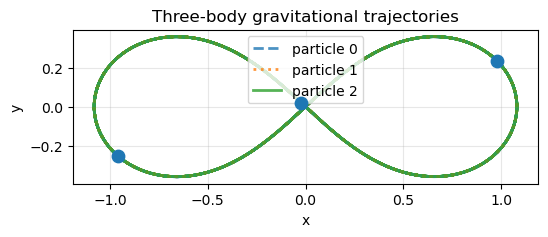

In [14]:
plt.figure(figsize=(6,6))

styles = ["--", ":", "-"]
for i in range(3):
    x = r_traj[:, i, 0]
    y = r_traj[:, i, 1]
    plt.plot(x, y, linestyle=styles[i], alpha=0.8, lw=2, label=f"particle {i}", zorder=1+i)

t = n // 2
plt.scatter(r_traj[t, :, 0], r_traj[t, :, 1], s=80, zorder=10)

plt.xlabel("x"); plt.ylabel("y")
plt.title("Three-body gravitational trajectories")
plt.legend()
plt.gca().set_aspect("equal", adjustable="box")
plt.grid(True, alpha=0.3)
plt.show()

The cell below animates the movement of the objects.

RuntimeError: x must be a sequence

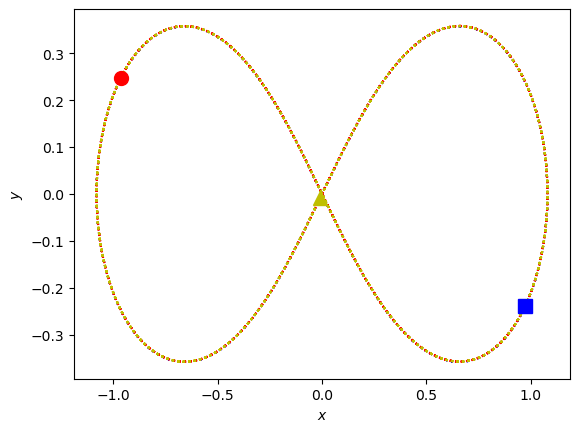

In [15]:
fig, ax = plt.subplots()

symbols = ["s","o","^"]
colours = ["b","r","y"]
n_particles = r.shape[0]

for i in range(n_particles):
    ax.plot(r_traj[:,i,0],r_traj[:,i,1],colours[i]+":")

points = [ax.plot(r_traj[0,i,0],r_traj[0,i,1],colours[i]+symbols[i],markersize=10)[0]
    for i in range(n_particles)]

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")

def animate(i):
    for j,p in enumerate(points):
        p.set_xdata(r_traj[i,j,0])
        p.set_ydata(r_traj[i,j,1])
        
    
    return tuple(points)

ani = animation.FuncAnimation(
    fig, animate, frames=n,interval=5, blit=True)

plt.show()

Let's now investigate how a change in simulation timestep impacts modelling the three body problem. Run a series of simulations with increasing timesteps $k\Delta t$, where $k = 1, 2, 4, 8, 16$. Consequently, the number of timesteps should be decreased to $n/k$, i.e. the total simulated time $T$ remains the same: $T = n \Delta t$.

Store the trajectories in the dictionary `r_traj_stable`, where the labels are `k`. In this cell, start the simulation from the figure-8 initial conditions.

In [18]:
dt = 0.01
n = 4000

r_stable = np.array(
[
    [0.97000436,-0.24308753],
    [-0.97000436,0.24308753],
    [0,0]
])

#These initial conditions should result in an 8-shaped trajectory
v_stable = np.array(
[
   [0.466203685,0.43236573],
   [0.466203685,0.43236573],
   [-0.93240737,-0.86473146]
])

r_traj_stable = {}

for k in [1,2,4,8,16]:
    r_traj_stable[k] = run(n // k, r_stable, v_stable, gravity, dt=dt*k, zero_momentum=False)
# The shape of r_traj is (number of steps, number of particles, dimensionality) where dimensionality is 2.

Evaluate the distance of the trajectories compared to the reference trajectory with the smallest timestep ($k=1$), sampled at $16 \Delta t$ time intervals. This means that for the trajectory with $k=1$, you need to take every 16-th timestep only. For $k=2$, you need to take every 8-th, and so on. Calculate the distance at the $i$-th sample as

$$
d^k_i = \sqrt{\frac{1}{i}\sum_j^i|\mathbf{r}^k_{\frac{16j}{k}} - \mathbf{r}^0_{16j}|^2}
$$

where $\mathbf{r}^k_j$ are the positions of the particles in trajectory run with the $k\Delta t$ timestep, at the $j$-th step. Store the results (which should be a `numpy` array for every `k`) in dictionary `d_stable`, where the keys are `k`.

In [19]:
d_stable = {}

ref_traj = r_traj_stable[1][::16]

for k in [1,2,4,8,16]:
    traj_k = r_traj_stable[k][::16//k]

    # truncate arrays to same no. of samples
    ns = min(len(ref_traj), len(traj_k))
    ref_k = ref_traj[:ns]
    traj_k = traj_k[:ns]

    # difference between kth traj and ref. at each matched sample time
    delta = traj_k - ref_k

    # squared Euclidean distance per sample summed over all particles and spatial coords
    sq_euclid = np.sum(delta ** 2, axis=(1,2))

    cumsum_sq = np.cumsum(sq_euclid)
    i = np.arange(1, ns + 1)
    d_stable[k] = np.sqrt(cumsum_sq / i)

Plot the results on the same graph: the distance against the timesteps. I recommend a logarithmic scale on the $y$ axis.

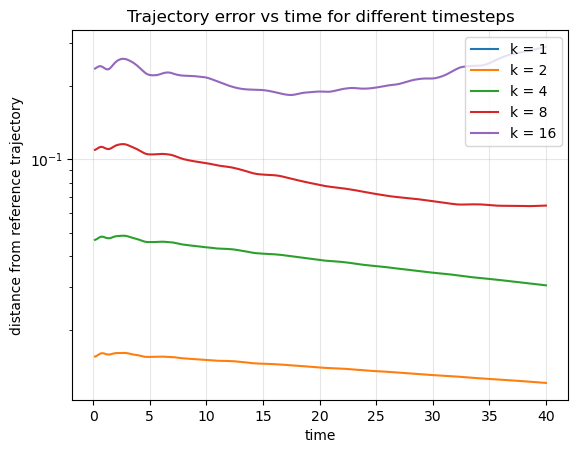

In [20]:
plt.figure()

for k in [1, 2, 4, 8, 16]:
    t = np.arange(1, len(d_stable[k]) + 1) * 16 * dt
    plt.plot(t, d_stable[k], label=f'k = {k}')

plt.yscale('log')
plt.xlabel('time')
plt.ylabel('distance from reference trajectory')
plt.title('Trajectory error vs time for different timesteps')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Now repeat the same procedure, but start the trajectories from initial conditions that lead to chaotic behaviour.

In [21]:
dt = 0.01
n = 4000

r_chaotic = np.array(
[
    [0.97000436,-0.24308753],
    [-0.97000436,0.24308753],
    [0,0]
])

# These initial conditions should result in a chaotic trajectory
v_chaotic = np.array([[ 0.38707758,  0.41898729],
       [ 0.55460722,  0.4670415 ],
       [-0.9416848 , -0.88602879]])


r_traj_chaotic = {}

for k in [1, 2, 4, 8, 16]:
    dt_k = k * dt
    n_k = n // k

    r_traj_chaotic[k] = run(
        n_k,
        r_chaotic,
        v_chaotic,
        gravity,
        dt=dt_k,
        zero_momentum=False
    )

# The shape of r_traj is (number of steps, number of particles, dimensionality) where dimensionality is 2.


As above, evaluate the distance of the trajectories compared to the reference trajectory with the smallest timestep ($k=1$), sampled at $16 \Delta t$ time intervals. This means that for the trajectory with $k=1$, you need to take every 16-th timestep only. For $k=2$, you need to take every 8-th, and so on. Calculate the distance at the $i$-th sample as

$$
d^k_i = \sqrt{\frac{1}{i}\sum_j^i|\mathbf{r}^k_{\frac{16j}{k}} - \mathbf{r}^0_{16j}|^2}
$$

where $\mathbf{r}^k_j$ are the positions of the particles in trajectory run with the $k\Delta t$ timestep, at the $j$-th step. Store the results (which should be a `numpy` array for every `k`) in dictionary `d_chaotic`, where the keys are `k`.

In [22]:
d_chaotic = {}
ref = r_traj_chaotic[1][::16]

for k in [1, 2, 4, 8, 16]:
    traj_k = r_traj_chaotic[k][::(16 // k)]

    ns = min(len(ref), len(traj_k))
    ref_k = ref[:ns]
    traj_k = traj_k[:ns]

    # Difference from the reference at each matched sample time.
    diff = traj_k - ref_k

    # Squared Euclidean distance at each sample,
    # summed over all particles and both spatial coordinates.
    sq_euclid = np.sum(diff**2, axis=(1, 2))

    # Running mean-square distance up to sample i, then take the square root.
    cumsum_sq = np.cumsum(sq_euclid)
    i = np.arange(1, ns + 1)

    d_chaotic[k] = np.sqrt(cumsum_sq / i)

Plot the results on the same graph: the distance against the timesteps. I recommend a logarithmic scale on the $y$ axis.

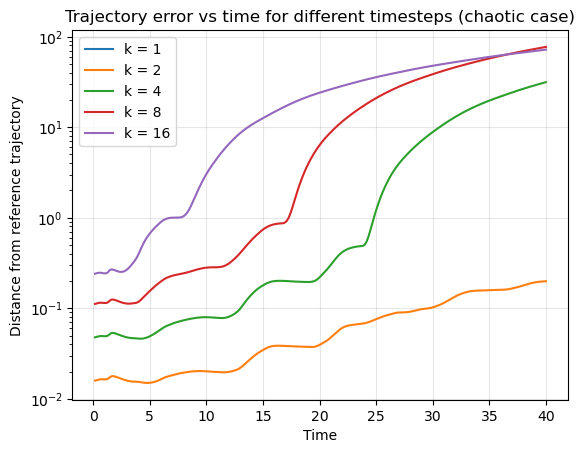

In [23]:
plt.figure()

for k in [1, 2, 4, 8, 16]:
    t = np.arange(1, len(d_chaotic[k]) + 1) * 16 * dt
    plt.plot(t, d_chaotic[k], label=f'k = {k}')

plt.yscale('log')
plt.xlabel('Time')
plt.ylabel('Distance from reference trajectory')
plt.title('Trajectory error vs time for different timesteps (chaotic case)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Discuss what you found in the last two simulations:
- How did the trajectories differ when using different timesteps?
- As the simulation progressed, what happened to the accuracy of the trajectories?
- What is the key difference between the stable (figure-8) simulation and the chaotic simulation?


Larger timesteps produce trajectories that deviate more strongly from the reference trajectory obtained with the smallest timestep. Smaller timestep simulations are closer to the reference solution for a longer time period, whereas simulations with larger timesteps diverge earlier. This behaviour indicates that the numerical integration error increases with timestep size.

In the stable figure-8 case, the trajectories computed with different timesteps remain close to the reference trajectory for a relatively long duration, and the error grows gradually and smoothly. This indicates that the numerical method reproduces the qualitative dynamics of the system reasonably well when sufficiently small timesteps are used.

On the other hand, the chaotic initial conditions lead to a much faster growth of the distance from the reference trajectory. Small numerical differences introduced by the timestep are rapidly amplified due to the system’s sensitivity to initial conditions. Consequently, trajectories computed with different timesteps diverge much earlier in the chaotic case.

Whilst reducing the timestep improves numerical accuracy in both cases, chaotic dynamics strongly amplify numerical errors and propagate through the simulation, making long-term trajectory prediction much more sensitive to timestep choice.

In the next example we model the motion of a star, a planet around it, the planet's moon. I gave the initial conditions below - collect a trajectory and inspect it.

In [24]:
m = np.array([1,0.0338765,0.00001])#,0.0001])

r = np.array(
[
    [0.,0.],
    [1.,0.],
    [1+7/45,0]
])
v = np.array(
[
    [0.,0.],
    [0.,1.],
    [0,1-7/15]
])

dt = 0.01
n = 6000

r_traj = run(n, r, v, gravity, dt=dt, zero_momentum=False)

Plot the trajectories of the objects below. 

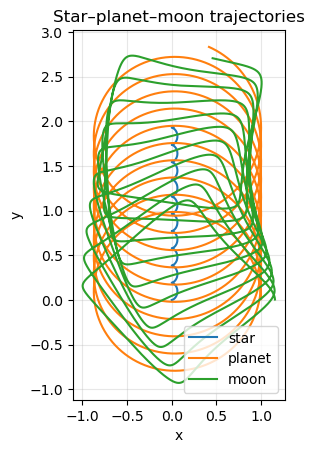

In [25]:
plt.figure()

labels = ["star", "planet", "moon"]

for i in range(3):
    plt.plot(r_traj[:, i, 0], r_traj[:, i, 1], label=labels[i])

plt.xlabel("x")
plt.ylabel("y")
plt.title("Star–planet–moon trajectories")
plt.legend()
plt.gca().set_aspect("equal")
plt.grid(True, alpha=0.3)

plt.show()

The cell below animates the movement of the objects.

RuntimeError: x must be a sequence

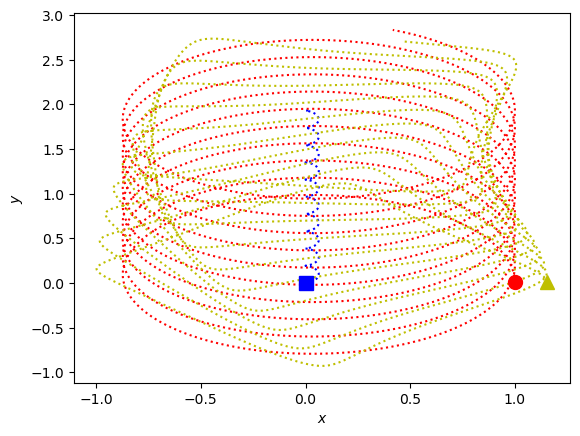

In [26]:
fig, ax = plt.subplots()

symbols = ["s","o","^"]
colours = ["b","r","y"]
n_particles = r.shape[0]

for i in range(n_particles):
    ax.plot(r_traj[:,i,0],r_traj[:,i,1],colours[i]+":")

points = [ax.plot(r_traj[0,i,0],r_traj[0,i,1],colours[i]+symbols[i],markersize=10)[0]
    for i in range(n_particles)]

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")

def animate(i):
    for j,p in enumerate(points):
        p.set_xdata(r_traj[i,j,0])
        p.set_ydata(r_traj[i,j,1])
        
    
    return tuple(points)

ani = animation.FuncAnimation(
    fig, animate, frames=n,interval=5, blit=True)

plt.show()

What are the orbits of the objects like? Why?


The trajectories show an orbital structure governed by mass. The star has the largest mass, moving slightly near the system's centre of mass. This is a result of having a significantly larger mass than the planet and moon, so the gravitational forces from the smaller bodies produce little acceleration.

The planet follows an elliptical orbit around the star, slightly perturbed by the moons gravitational influence. This causes small deviations from a typical two-body orbit. The moon orbits the planet as the planet is orbiting the star. In turn, the moon has an epicyclical orbit path as a result of the superposition of the moon's orbit around the planet and the planet's orbit around the star.

## Structural quantities
Structural quantities may be calculated from sample configurations, and averaged. The radial distribution function (RDF) is related to the structure factor, which is observable from scattering experiments. On a set of configurations it can be obtained using this formula:
$$
g(r) = \left \langle  \frac{1}{N} \sum_{ij} \delta( r - r_{ij} ) \right\rangle_\textrm{ensemble}
$$
Execute the cells below, illustrating how the $g(r)$ can be calculated:

In [27]:
from ase.lattice.cubic import Diamond, FaceCenteredCubic, BodyCenteredCubic
from ase.lattice.hexagonal import HexagonalClosedPacked

In [28]:
from ase.visualize import view

In [29]:
# start with a fresh diamond configuration
diamond = Diamond("C")

# ASE can calculate the interatomic distances in a configuration
from ase.neighborlist import neighbor_list

cutoff = 6.0
# resulting in a list of all pairwise distances:
d = neighbor_list('d', diamond, cutoff=cutoff)

In [30]:
# You should always look at your atoms - this command visualises them
view(diamond,viewer="x3d")

The cell below calculates the histogram of the pair-wise distances, and stores them in the `numpy` arrays `r` and `gr`.

In [31]:
# Define bins
r = np.linspace(0,cutoff,100,endpoint=True)

# Compute the histogram of the distances
h,x=np.histogram(d,bins=r)
gr = h/len(diamond)
r = (r[1:]+r[:-1])/2

Plot the $g(r)$ (RDF) of diamond.

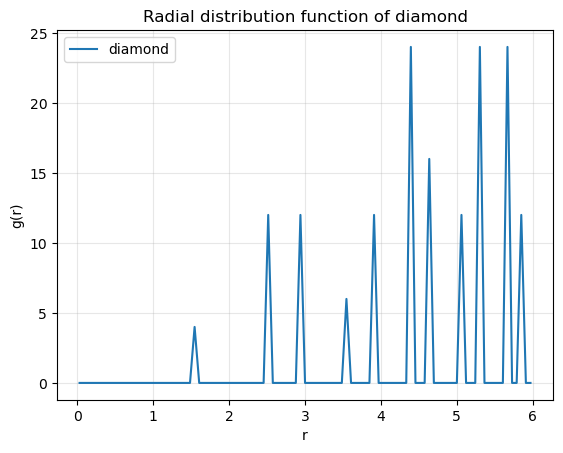

In [32]:
plt.figure()

plt.plot(r, gr, label="diamond")

plt.xlabel("r")
plt.ylabel("g(r)")
plt.title("Radial distribution function of diamond")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Now calculate and plot, on the same graph, the RDF of a diamond, face-centred cubic, body-centred cubic and hexagonal closed pack crystal.

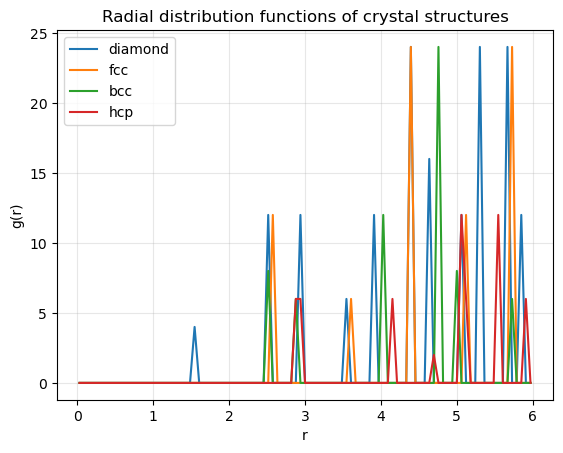

In [33]:
fcc = FaceCenteredCubic("Cu")
hcp = HexagonalClosedPacked("Ti")
bcc = BodyCenteredCubic("Fe")

plt.figure()

structures = {
    "diamond": diamond,
    "fcc": fcc,
    "bcc": bcc,
    "hcp": hcp,
}

for name, atoms in structures.items():
    d = neighbor_list('d', atoms, cutoff=cutoff)
    h, x = np.histogram(d, bins=np.linspace(0, cutoff, 100, endpoint=True))
    gr = h / len(atoms)
    r_plot = (x[1:] + x[:-1]) / 2
    plt.plot(r_plot, gr, label=name)

plt.xlabel("r")
plt.ylabel("g(r)")
plt.title("Radial distribution functions of crystal structures")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Compare the $g(r)$ (RDF) of the different crystals and discuss the differences and similarities you see. Relate these to the structure of the crystal.


The radial distribution functions show sharp peaks at discrete distances, reflecting the long range order present in crystalline solids. Each peak corresponds to a coordination shell of neighbouring atoms at a specific distance determined by the lattice geometry. The diamond structure has a distinct RDF compared to the others because each atom is tetrahedrally coordinated with four nearest neighbours. This lower coordination number produces a different position and height of the first peak compared to the more densely packed lattices.

The FCC and HCP structures exhibit very similar RDF patterns. Both are close packed lattices with a coordination number of twelve, so the first few neighbour distances are almost identical. The small differences between them arise from their different stacking sequences of atomic planes. The BCC structure differs from the close packed structures because it has eight nearest neighbours and a lower packing density. This leads to peaks at different positions that reflect the geometry of the body centred cubic lattice.